# Etapa 3 — Tratamento

Decisões tomadas:
- **Frequência mensal**, valor do **último dia útil do mês** (Focus: última pesquisa do mês).
- **Amostra**: variações de **jan/2009 a out/2026** (níveis a partir de dez/2008, para calcular a primeira variação).
- **Transformações**: 100·Δln para preços/índices (PTAX, dólar AFE, commodities, VIX, CDS); Δ simples para taxas e % do PIB (Treasury, Selic, Focus).
- **Testes**: ADF (H₀: raiz unitária) e KPSS (H₀: estacionária), nos níveis e nas variações.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

BRUTOS = Path("dados/brutos")
TRATADOS = Path("dados/tratados")
TRATADOS.mkdir(parents=True, exist_ok=True)

INICIO_NIVEIS = "2008-12-01"   # dez/2008 entra só para calcular a variação de jan/2009
FIM = "2026-10-31"             # último mês completo (dólar AFE vai até 30/10)

## 1. Leitura dos dados brutos

In [2]:
def ler(nome):
    return pd.read_csv(BRUTOS / nome, index_col=0, parse_dates=True)

ptax = ler("ptax_venda.csv")
selic = ler("selic_meta.csv")
cds = ler("cds_5a.csv")
bcom = ler("bcom.csv")
externas = ler("externas_fred.csv")   # ust10, vix, dolar_afe
focus = pd.read_csv(BRUTOS / "focus_primario.csv", parse_dates=["Data"])

## 2. Focus: horizonte fixo de 12 meses

Para cada pesquisa (data *t*, mês *m*):

$$E^{12m}_t = \frac{12-m}{12}\,E_t[\text{ano corrente}] + \frac{m}{12}\,E_t[\text{ano seguinte}]$$

Assim a variável olha sempre ~12 meses à frente e some o salto artificial de janeiro.

In [3]:
# Coloca cada ano de referência numa coluna: linhas = data da pesquisa, colunas = 2009, 2010, ...
tabela = focus.pivot_table(index="Data", columns="DataReferencia", values="Mediana")

def horizonte_fixo(data):
    ano, m = data.year, data.month
    corrente = tabela.loc[data, ano]
    seguinte = tabela.loc[data, ano + 1]
    return (12 - m) / 12 * corrente + m / 12 * seguinte

primario_12m = pd.Series([horizonte_fixo(d) for d in tabela.index], index=tabela.index, name="primario_12m")

# Conferência: na virada 2014 -> 2015 não deve haver salto
primario_12m["2014-12-20":"2015-01-15"].round(3)

Data
2014-12-22    1.000
2014-12-23    1.000
2014-12-24    1.000
2014-12-26    1.000
2014-12-29    1.000
2014-12-30    1.000
2014-12-31    1.000
2015-01-02    1.075
2015-01-05    1.067
2015-01-06    1.067
2015-01-07    1.067
2015-01-08    1.071
2015-01-09    1.075
2015-01-12    1.075
2015-01-13    1.075
2015-01-14    1.075
2015-01-15    1.075
Name: primario_12m, dtype: float64

## 3. Frequência mensal (último valor do mês)

`resample("ME").last()` pega, em cada mês, o **último valor não vazio** — os `NaN` de feriados são
ignorados automaticamente. O índice passa a ser o último dia do mês.

In [4]:
niveis = pd.concat(
    [
        ptax.resample("ME").last(),
        externas.resample("ME").last(),
        bcom.resample("ME").last(),
        selic.resample("ME").last(),
        cds.resample("ME").last(),
        primario_12m.resample("ME").last(),
    ],
    axis=1,
    sort=True,
).loc[INICIO_NIVEIS:FIM]

niveis = niveis[["ptax_venda", "ust10", "vix", "dolar_afe", "bcom", "selic_meta", "cds_5a", "primario_12m"]]
print("Faltantes por coluna:", niveis.isna().sum().to_dict())
niveis.tail()

Faltantes por coluna: {'ptax_venda': 0, 'ust10': 0, 'vix': 0, 'dolar_afe': 0, 'bcom': 0, 'selic_meta': 0, 'cds_5a': 0, 'primario_12m': 0}


,ptax_venda,ust10,vix,dolar_afe,bcom,selic_meta,cds_5a,primario_12m
2026-06-30,5.1766,4.44,16.45,114.2259,123.1774,14.25,125.23,-0.450000
2026-07-31,5.0773,4.75,15.99,112.8987,132.0536,14.25,125.90,-0.441667
2026-08-31,5.1816,4.75,14.92,112.0636,141.3656,14.00,121.08,-0.433333
2026-09-30,5.1809,5.29,16.34,114.3837,141.7847,13.75,131.21,-0.402500
2026-10-31,5.4212,4.94,19.42,114.3735,141.2057,13.75,141.02,-0.415000


## 4. Transformações

Nomes com prefixo `d` = variação. `dl_` = 100·Δln (≈ % ao mês); `d_` = Δ simples (p.p.).

In [5]:
def dlog(serie):
    """100 x diferença do log: aproximadamente a variação % no mês."""
    return 100 * np.log(serie).diff()

variacoes = pd.DataFrame({
    "dl_cambio":   dlog(niveis["ptax_venda"]),   # dependente: + = real se desvaloriza
    "d_ust10":     niveis["ust10"].diff(),       # externa (p.p.)
    "dl_vix":      dlog(niveis["vix"]),          # externa (%)
    "dl_dolar":    dlog(niveis["dolar_afe"]),    # externa (%)
    "dl_commod":   dlog(niveis["bcom"]),         # externa (%): commodities sobem → real tende a valorizar
    "d_selic":     niveis["selic_meta"].diff(),  # doméstica (p.p.)
    "dl_cds":      dlog(niveis["cds_5a"]),       # doméstica (%) — será "limpa" na etapa 5
    "d_primario":  niveis["primario_12m"].diff() # doméstica (p.p. do PIB; + = melhora fiscal esperada)
}).dropna()   # remove dez/2008, que não tem variação

print("Período:", variacoes.index[0].date(), "->", variacoes.index[-1].date(), "| meses:", len(variacoes))
variacoes.describe().T.round(2)

Período: 2009-01-31 -> 2026-10-31 | meses: 214


,count,mean,std,min,25%,50%,75%,max
dl_cambio,214.0,0.39,4.28,-11.34,-2.44,0.24,3.10,15.56
d_ust10,214.0,0.01,0.24,-0.59,-0.14,0.01,0.16,0.68
dl_vix,214.0,-0.34,22.66,-61.43,-15.46,-1.26,12.05,85.26
dl_dolar,214.0,0.09,2.00,-6.96,-1.31,0.10,1.53,5.76
dl_commod,214.0,0.09,4.30,-15.94,-2.32,0.23,2.58,12.21
d_selic,214.0,0.00,0.44,-1.50,0.00,0.00,0.00,1.50
dl_cds,214.0,-0.36,13.97,-35.29,-9.35,-0.92,7.21,67.64
d_primario,214.0,-0.02,0.34,-4.11,-0.05,0.01,0.05,0.96


## 5. Olhar antes de testar

Sempre vale **ver** as séries: níveis à esquerda (tendências, quebras) e variações à direita
(devem oscilar em torno de uma média constante).

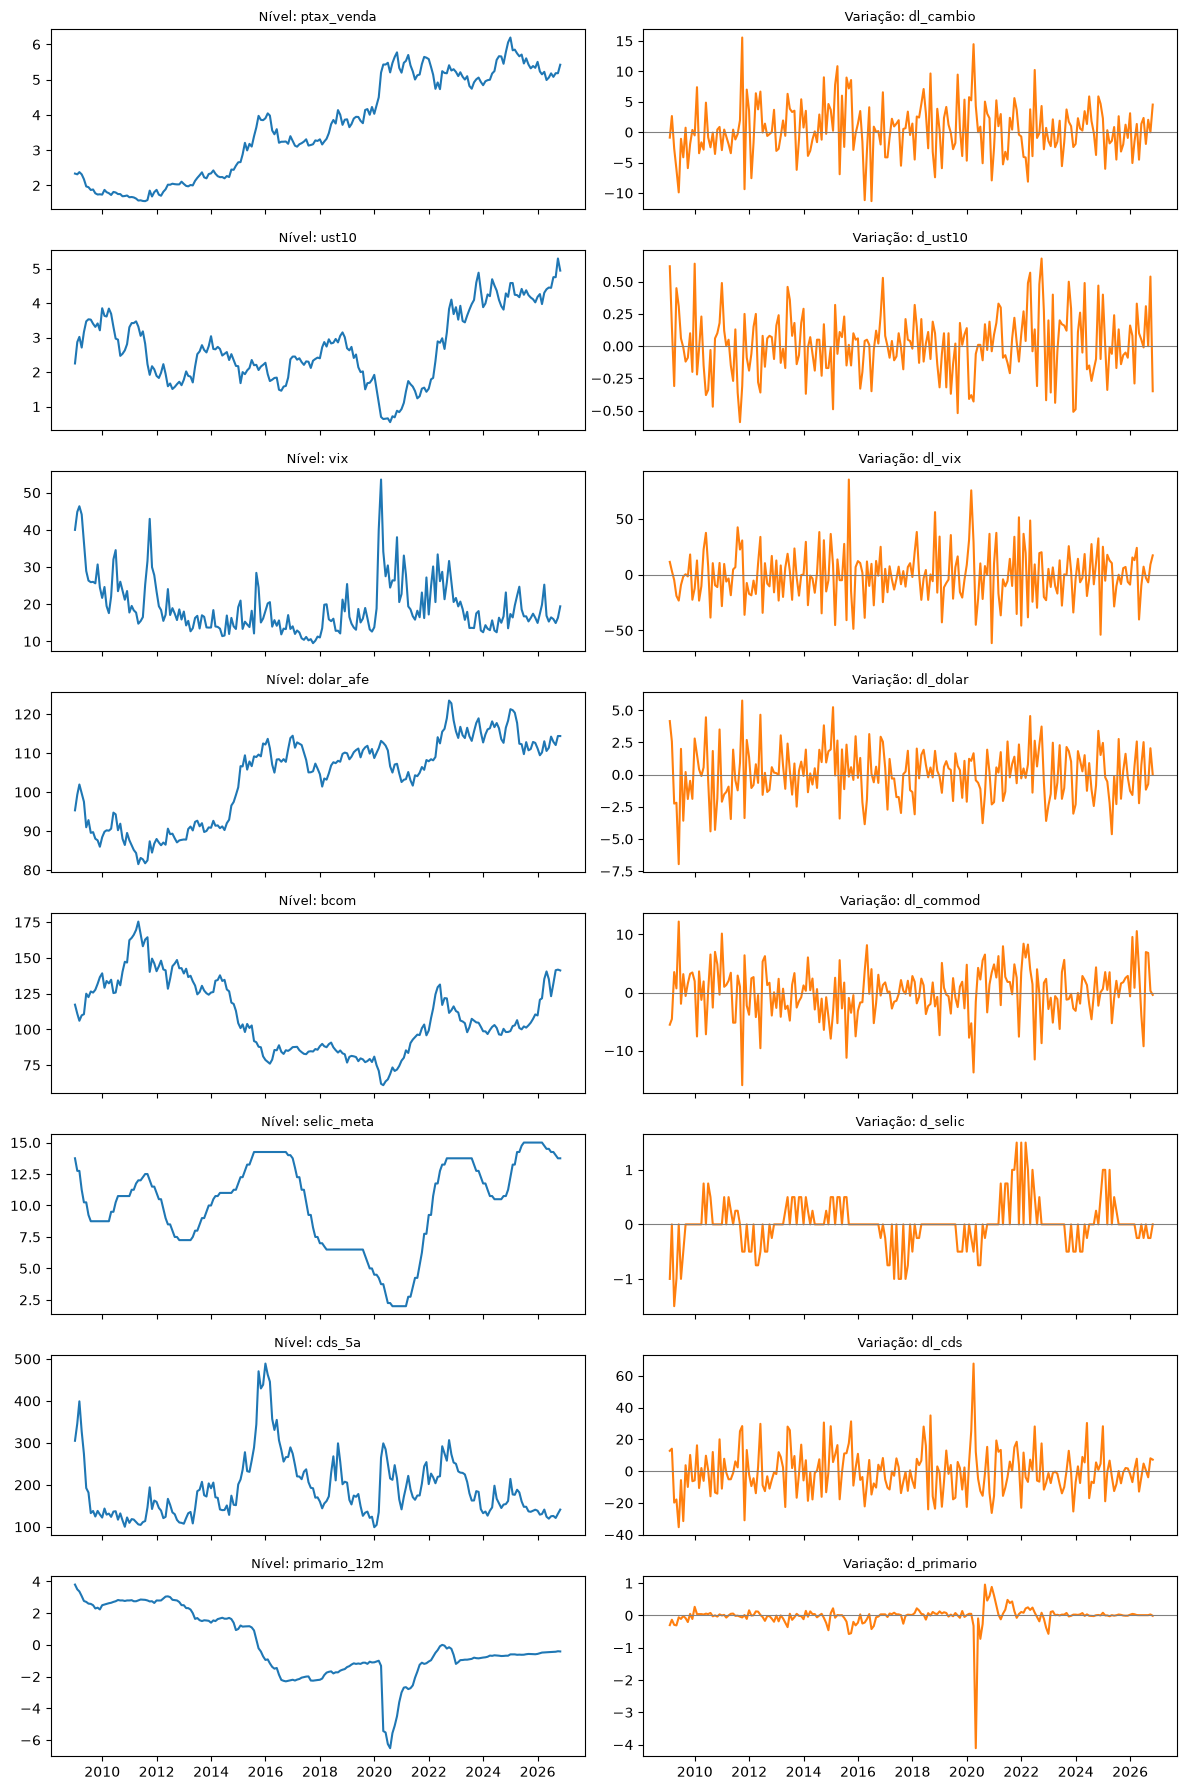

In [6]:
fig, eixos = plt.subplots(len(variacoes.columns), 2, figsize=(12, 18), sharex=True)
for i, (col_nivel, col_var) in enumerate(zip(niveis.columns, variacoes.columns)):
    eixos[i, 0].plot(niveis[col_nivel], color="tab:blue")
    eixos[i, 0].set_title(f"Nível: {col_nivel}", fontsize=9)
    eixos[i, 1].plot(variacoes[col_var], color="tab:orange")
    eixos[i, 1].axhline(0, color="gray", lw=0.8)
    eixos[i, 1].set_title(f"Variação: {col_var}", fontsize=9)
fig.tight_layout()
plt.show()

## 6. Testes de estacionariedade

| Teste | H₀ | O que queremos ver numa série estacionária |
|---|---|---|
| ADF | tem raiz unitária (não estacionária) | p-valor **< 0,05** (rejeita) |
| KPSS | é estacionária | p-valor **> 0,05** (não rejeita) |

O KPSS só reporta p-valores entre 0,01 e 0,10 (tabela interpolada). Fora disso ele avisa e
devolve o limite — por isso silenciamos o aviso; leia "0,01" como "≤ 0,01" e "0,10" como "≥ 0,10".

In [7]:
def testar(serie):
    serie = serie.dropna()
    p_adf = adfuller(serie, autolag="AIC", result_object=False)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        p_kpss = kpss(serie, regression="c", nlags="auto", result_object=False)[1]
    if p_adf < 0.05 and p_kpss > 0.05:
        conclusao = "estacionária"
    elif p_adf >= 0.05 and p_kpss <= 0.05:
        conclusao = "NÃO estacionária"
    else:
        conclusao = "inconclusivo"
    return {"p ADF": round(p_adf, 3), "p KPSS": round(p_kpss, 3), "conclusão": conclusao}

# Níveis na mesma escala usada nas variações (log para preços/índices)
niveis_teste = {
    "ln(ptax)": np.log(niveis["ptax_venda"]), "ust10": niveis["ust10"], "ln(vix)": np.log(niveis["vix"]),
    "ln(dolar_afe)": np.log(niveis["dolar_afe"]), "ln(bcom)": np.log(niveis["bcom"]), "selic_meta": niveis["selic_meta"],
    "ln(cds)": np.log(niveis["cds_5a"]), "primario_12m": niveis["primario_12m"],
}

resultado = pd.concat(
    [
        pd.DataFrame({nome: testar(s) for nome, s in niveis_teste.items()}).T,
        pd.DataFrame({nome: testar(variacoes[nome]) for nome in variacoes.columns}).T,
    ],
    keys=["Níveis", "Variações"],
)
resultado

p ADF p KPSS         conclusão
Níveis    ln(ptax)       0.881   0.01  NÃO estacionária
          ust10          0.733  0.023  NÃO estacionária
          ln(vix)          0.0    0.1      estacionária
          ln(dolar_afe)  0.635   0.01  NÃO estacionária
          ln(bcom)       0.714   0.01  NÃO estacionária
          selic_meta     0.009    0.1      estacionária
          ln(cds)        0.021    0.1      estacionária
          primario_12m   0.364   0.01  NÃO estacionária
Variações dl_cambio        0.0    0.1      estacionária
          d_ust10          0.0    0.1      estacionária
          dl_vix           0.0    0.1      estacionária
          dl_dolar         0.0    0.1      estacionária
          dl_commod        0.0    0.1      estacionária
          d_selic        0.013    0.1      estacionária
          dl_cds           0.0    0.1      estacionária
          d_primario       0.0    0.1      estacionária

## 7. Salvar

In [8]:
niveis.to_csv(TRATADOS / "niveis_mensais.csv")
variacoes.to_csv(TRATADOS / "variacoes_mensais.csv")
print("Arquivos salvos em", TRATADOS)

Arquivos salvos em dados\tratados
